# Replicate DEG Metric Violins

This notebook reads the precomputed replicate DEG outputs and plots per-dataset violins and heatmaps. Summary tables below each violin report means/medians for observed scores, centroid baselines, and peer baselines.

Each distribution uses all of its available scores independently. Summary and heatmap deltas average the precomputed paired observed-minus-baseline differences.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

def find_repo_root(start=None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "results").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from the current working directory.")


REPO_ROOT = find_repo_root()
RESULTS_DIR = REPO_ROOT / "results" / "replicate_signature_similarity_sep_rep"


DATASET_ORDER = [
    "cigs_mce",
    "cigs_tcm",
    "dilimap_train_val",
    "gdpx2",
    
    
    "l1000_phase1",
    "l1000_phase2",
    
    "novartis_batch_2500",
    "op3",
    "sciplex",
    "tahoe",
    "vcpi_0001",
    "vcpi_0002",
    
    
    
]
PRETTY_LABELS = {
    "l1000_phase1": "L1000 Phase I",
    "l1000_phase2": "L1000 Phase II",
    "tahoe": "Tahoe-100M",
    "cigs_mce": "CIGS-MCE",
    "novartis_batch_2500": "Novartis/DRUG-seq U2OS",
    "vcpi_0001": "VCPI-0001",
    "cigs_tcm": "CIGS-TCM",
    "vcpi_0002": "VCPI-0002",
    "gdpx2": "GDPx2",
    "sciplex": "sci-Plex",
    "dilimap_train_val": "DILImap",
    "op3": "OP3",
}
DATASET_ORDER_MAP = {dataset_name: idx for idx, dataset_name in enumerate(DATASET_ORDER)}

sns.set_theme(style="whitegrid", context="talk")


def pretty_label(dataset_name: str) -> str:
    return PRETTY_LABELS.get(str(dataset_name), str(dataset_name))


def dataset_names_in_order(frame: pd.DataFrame) -> list[str]:
    present = set(frame["dataset_name"].dropna().astype(str).unique().tolist())
    ordered = [dataset_name for dataset_name in DATASET_ORDER if dataset_name in present]
    ordered.extend(sorted(dataset_name for dataset_name in present if dataset_name not in DATASET_ORDER_MAP))
    return ordered


def dataset_label_order(frame: pd.DataFrame) -> list[str]:
    return [pretty_label(dataset_name) for dataset_name in dataset_names_in_order(frame)]


def sort_by_dataset_order(frame: pd.DataFrame) -> pd.DataFrame:
    sort_frame = frame.copy()
    sort_frame["_dataset_order"] = sort_frame["dataset_name"].astype(str).map(DATASET_ORDER_MAP).fillna(len(DATASET_ORDER))
    return (
        sort_frame.sort_values(["_dataset_order", "dataset_name"])
        .drop(columns="_dataset_order")
        .reset_index(drop=True)
    )

In [2]:
def plot_violin_with_baseline(frame: pd.DataFrame, *, observed_col: str, baseline_col: str, peer_baseline_col: str, centroid_delta_col: str, peer_delta_col: str | None, title: str, ylabel: str, pdf_name: str) -> pd.DataFrame:
    column_map = {
        observed_col: "observed",
        baseline_col: "centroid baseline",
        centroid_delta_col: "delta_centroid",
    }
    if peer_baseline_col is not None:
        if peer_delta_col is None:
            raise ValueError("peer_delta_col is required when a peer baseline is supplied.")
        column_map[peer_baseline_col] = "peer baseline"
        column_map[peer_delta_col] = "delta_peer"
    required_columns = {"dataset_name", "condition_key", *column_map}
    missing = sorted(required_columns - set(frame.columns))
    if missing:
        raise KeyError(f"Missing columns for plot {title!r}: {missing}")
    plot_frame = frame[["dataset_name", "condition_key", *column_map]].copy()
    plot_frame = plot_frame.rename(columns=column_map)
    if peer_baseline_col is None:
        plot_frame["peer baseline"] = float("nan")
        plot_frame["delta_peer"] = float("nan")
    plot_frame["dataset_label"] = plot_frame["dataset_name"].map(pretty_label)
    # Keep all conditions: each score distribution has its own missing values.
    if not plot_frame[["observed", "centroid baseline", "peer baseline"]].notna().any().any():
        raise ValueError(f"No score values available for plot {title!r}.")
    observed_frame = plot_frame.loc[plot_frame["observed"].notna()].copy()
    observed_count_by_dataset = observed_frame.groupby("dataset_name")["condition_key"].nunique()

    order = dataset_label_order(plot_frame)
    fig_width = max(10.0, 1.35 * len(order) + 2.0)
    fig, ax = plt.subplots(figsize=(fig_width, 6.4))

    baseline_frame = plot_frame.loc[plot_frame["centroid baseline"].notna()].copy()
    peer_baseline_frame = plot_frame.loc[plot_frame["peer baseline"].notna()].copy()
    baseline_count_by_dataset = baseline_frame.groupby("dataset_name")["condition_key"].nunique() if not baseline_frame.empty else pd.Series(dtype=int)
    peer_baseline_count_by_dataset = peer_baseline_frame.groupby("dataset_name")["condition_key"].nunique() if not peer_baseline_frame.empty else pd.Series(dtype=int)
    
    
    observed_violin_frame = observed_frame[["dataset_name", "dataset_label", "condition_key", "observed"]].rename(columns={"observed": "score"})
    observed_violin_frame["score_type"] = "Cross replicate"
    baseline_violin_frame = baseline_frame[["dataset_name", "dataset_label", "condition_key", "centroid baseline"]].rename(columns={"centroid baseline": "score"})
    baseline_violin_frame["score_type"] = "Centroid Baseline"
    peer_baseline_violin_frame = peer_baseline_frame[["dataset_name", "dataset_label", "condition_key", "peer baseline"]].rename(columns={"peer baseline": "score"})
    peer_baseline_violin_frame["score_type"] = "Peer Baseline"
    violin_frame = pd.concat([observed_violin_frame, baseline_violin_frame, peer_baseline_violin_frame], ignore_index=True)
    hue_order = ["Cross replicate", "Centroid Baseline", "Peer Baseline"] if not (baseline_violin_frame.empty and peer_baseline_violin_frame.empty) else ["Cross replicate"]

    sns.violinplot(
        data=violin_frame,
        x="dataset_label",
        y="score",
        hue="score_type",
        order=order,
        hue_order=hue_order,
        inner=None,
        cut=0,
        linewidth=1.0,
        palette={"Cross replicate": "#dbe9f6", "Centroid Baseline": "#f4c7c3", "Peer Baseline": "#d9ead3"},
        dodge=True,
        ax=ax,
    )

    summary = plot_frame.groupby(["dataset_name", "dataset_label"], as_index=False).agg(
        n_conditions=("condition_key", "nunique"),
        observed_mean=("observed", "mean"),
        observed_median=("observed", "median"),
        centroid_baseline_mean=("centroid baseline", "mean"),
        centroid_baseline_median=("centroid baseline", "median"),
        peer_baseline_mean=("peer baseline", "mean"),
        peer_baseline_median=("peer baseline", "median"),
        # These columns already average paired differences within each condition.
        delta_centroid=("delta_centroid", "mean"),
        delta_peer=("delta_peer", "mean"),
    )
    
    summary = sort_by_dataset_order(summary)
    summary["n_conditions_with_observed"] = summary["dataset_name"].map(observed_count_by_dataset).fillna(0).astype(int)
    summary["n_conditions_with_centroid_baseline"] = summary["dataset_name"].map(baseline_count_by_dataset).fillna(0).astype(int)
    summary["n_conditions_with_peer_baseline"] = summary["dataset_name"].map(peer_baseline_count_by_dataset).fillna(0).astype(int)
    if ax.get_legend() is not None:
        ax.legend(title="", loc="lower right", frameon=True)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=35)
    sns.despine(ax=ax)
    fig.tight_layout()
    out_path = RESULTS_DIR / pdf_name
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"Saved plot to {out_path}")
    zero_baseline_c = summary.loc[summary["n_conditions_with_centroid_baseline"] == 0, "dataset_label"].tolist()
    zero_baseline_p = summary.loc[summary["n_conditions_with_peer_baseline"] == 0, "dataset_label"].tolist()
    if zero_baseline_c:
        print("No baseline-scored conditions in:", ", ".join(zero_baseline_c))
    if zero_baseline_p:
        print("No baseline-scored conditions in:", ", ".join(zero_baseline_p))
    display(summary)
    return summary

In [3]:
def plot_summary_heatmap(
    summary: pd.DataFrame,
    *,
    title: str,
    value_label: str,
    pdf_name: str,
    vmin=None,
    vmax=None,
    show_colorbar: bool = True,
    show_dataset_labels: bool = True,
) -> pd.DataFrame:
    required_columns = {"dataset_name", "dataset_label", "observed_mean", "centroid_baseline_mean", "peer_baseline_mean", "delta_centroid", "delta_peer"}
    missing = sorted(required_columns - set(summary.columns))
    if missing:
        raise KeyError(f"Missing columns for heatmap {title!r}: {missing}")

    # Deltas are means of precomputed paired differences, as in the tables.
    summary_frame = summary.copy()

    summary_frame = sort_by_dataset_order(summary_frame)

    heatmap_frame = summary_frame[["dataset_label", 
                                   "observed_mean", 
                                   "centroid_baseline_mean", 
                                   "peer_baseline_mean", 
                                   "delta_centroid", 
                                   "delta_peer"]].rename(
        columns={
            "dataset_label": "Dataset",
            "observed_mean": "Observed",
            "centroid_baseline_mean": "Centroid baseline",
            "peer_baseline_mean": "Peer baseline",
            "delta_centroid": r'$\Delta$ centroid',
            "delta_peer": r'$\Delta$ peer',

        }
    ).set_index("Dataset")

    fig, ax = plt.subplots(figsize=(8.6, max(4.5, 1.0 * len(heatmap_frame))))
    sns.heatmap(
        heatmap_frame,
        annot=True,
        fmt=".3f",
        cmap="RdBu_r",
        center=0.0,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        linecolor="white",
        cbar=show_colorbar,
        cbar_kws={"label": value_label} if show_colorbar else {},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    if show_dataset_labels:
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    else:
        ax.tick_params(axis="y", labelleft=False, length=0)
    fig.tight_layout()
    out_path = RESULTS_DIR / pdf_name
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"Saved heatmap to {out_path}")
    display(heatmap_frame)
    return heatmap_frame

In [4]:
def shared_summary_heatmap_limits(*summaries: pd.DataFrame) -> tuple[float, float]:
    values = []
    for summary in summaries:
        summary_frame = summary.copy()

        values.append(summary_frame[["observed_mean", "centroid_baseline_mean", "peer_baseline_mean", "delta_centroid", "delta_peer"]].stack())
    all_values = pd.concat(values).dropna()
    if all_values.empty:
        raise ValueError("No finite values available for shared heatmap limits.")
    return float(all_values.min()), float(all_values.max())

In [5]:
condition_deg_metric_summary = pd.read_csv(RESULTS_DIR / 'condition_deg_metric_summary.tsv', sep='	')

required_direction_cols = [
    'mean_replicate_direction_agreement_p05',
    'mean_baseline_pair_direction_agreement_p05',
    'mean_peer_baseline_direction_agreement_p05',
    'mean_delta_vs_baseline_pair_direction_agreement_p05',
    'mean_delta_vs_peer_baseline_direction_agreement_p05',
]
missing_direction_cols = [column_name for column_name in required_direction_cols if column_name not in condition_deg_metric_summary.columns]
if missing_direction_cols:
    condition_metric_summary = pd.read_csv(RESULTS_DIR / 'condition_metric_summary.tsv', sep='	')
    merge_keys = ['dataset_name', 'condition_key']
    available_merge_columns = [
        column_name
        for column_name in missing_direction_cols
        if column_name in condition_metric_summary.columns
    ]
    if all(column_name in condition_metric_summary.columns for column_name in merge_keys) and available_merge_columns:
        condition_deg_metric_summary = condition_deg_metric_summary.merge(
            condition_metric_summary[merge_keys + available_merge_columns].drop_duplicates(merge_keys),
            on=merge_keys,
            how='left',
        )
print(
    f"Loaded {len(condition_deg_metric_summary):,} DEG condition rows across "
    f"{condition_deg_metric_summary['dataset_name'].nunique():,} datasets from {RESULTS_DIR}."
)

condition_deg_metric_summary.head()

Loaded 84,315 DEG condition rows across 12 datasets from /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep.


,dataset_name,cell_type,pubchem_cid,time_key,dose_key,condition_key,perturbagen_display,n_replicates,n_replicate_pairs,n_source_files,...,median_replicate_deg_lfc_spearman_sym_p05,median_replicate_direction_agreement_p05,mean_baseline_pair_deg_t_spearman_sym_p05,mean_delta_vs_baseline_pair_deg_t_spearman_sym_p05,mean_delta_vs_peer_baseline_deg_t_spearman_sym_p05,mean_peer_baseline_deg_t_spearman_sym_corrected_percentile_p05,mean_peer_baseline_deg_t_spearman_sym_fraction_below_observed_p05,mean_peer_baseline_deg_t_spearman_sym_p05,mean_peer_baseline_deg_t_spearman_sym_sd_p05,mean_replicate_deg_t_spearman_sym_p05
0,dilimap_train_val,CL_0000182,444,24,3.703704,CL_0000182|444|24|3.7037037037,Bupropion,2,1,1,...,0.276254,1.0,0.370707,-0.020678,0.255966,0.908714,0.908333,0.094063,0.183241,0.350029
1,dilimap_train_val,CL_0000182,444,24,11.000000,CL_0000182|444|24|11,Bupropion,2,1,1,...,0.434212,NaN,0.431154,-0.069121,0.281880,0.813492,0.812749,0.080153,0.271497,0.362033
2,dilimap_train_val,CL_0000182,444,24,33.000000,CL_0000182|444|24|33,Bupropion,2,1,1,...,0.300101,NaN,0.360889,-0.073676,0.229352,0.741036,0.740000,0.057861,0.330341,0.287213
3,dilimap_train_val,CL_0000182,444,24,100.000000,CL_0000182|444|24|100,Bupropion,3,3,1,...,-0.036770,1.0,0.386294,0.086462,0.482242,0.878080,0.877604,-0.009486,0.349823,0.472756
4,dilimap_train_val,CL_0000182,1775,24,37.000000,CL_0000182|1775|24|37,Phenytoin,6,6,1,...,0.230807,1.0,0.461873,-0.216772,0.129656,0.783398,0.782552,0.115445,0.145483,0.245101


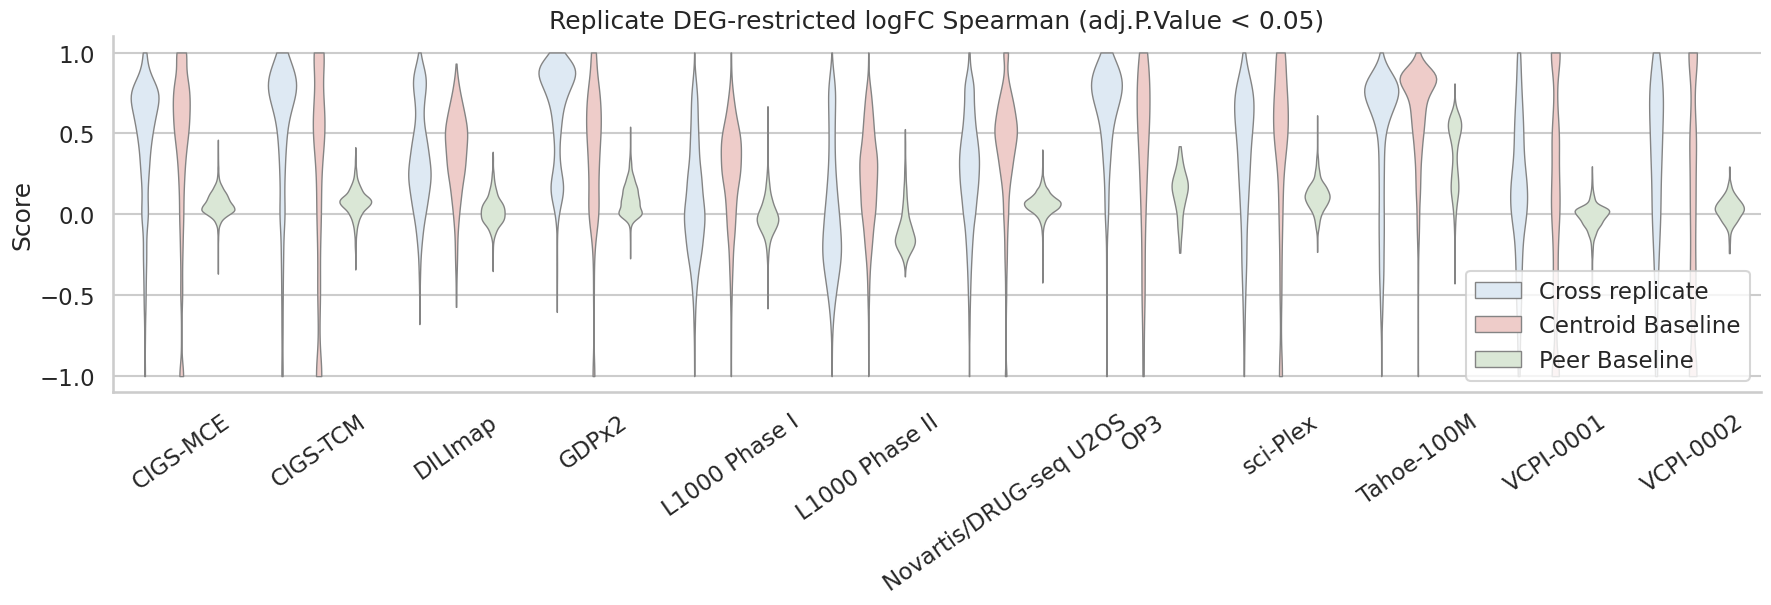

Saved plot to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/replicate_deg_lfc_spearman_p05_violin.pdf


,dataset_name,dataset_label,n_conditions,observed_mean,observed_median,centroid_baseline_mean,centroid_baseline_median,peer_baseline_mean,peer_baseline_median,delta_centroid,delta_peer,n_conditions_with_observed,n_conditions_with_centroid_baseline,n_conditions_with_peer_baseline
0,cigs_mce,CIGS-MCE,21426,0.454122,0.580388,0.430808,0.566667,0.063940,0.055314,-0.006977,0.390182,6368,13008,6368
1,cigs_tcm,CIGS-TCM,7020,0.543602,0.713830,0.285971,0.496500,0.073219,0.076208,0.160096,0.470383,1720,3353,1720
2,dilimap_train_val,DILImap,1184,0.347947,0.306972,0.374317,0.406434,0.025213,0.019151,-0.027539,0.322408,1181,1176,1173
3,gdpx2,GDPx2,2064,0.643370,0.776421,0.370705,0.443591,0.092086,0.078352,0.250806,0.551284,1086,1348,1086
4,l1000_phase1,L1000 Phase I,2517,0.085425,0.043902,0.256161,0.300000,-0.011585,-0.019810,-0.175011,0.094663,2447,2434,2371
5,l1000_phase2,L1000 Phase II,2729,0.012663,-0.065369,0.218361,0.232507,-0.091290,-0.125507,-0.207442,0.103732,2700,2726,2697
6,novartis_batch_2500,Novartis/DRUG-seq U2OS,15276,0.266138,0.287868,0.409245,0.472108,0.067373,0.066214,-0.144941,0.198765,12634,14721,12634
7,op3,OP3,541,0.631333,0.736061,0.391289,0.526809,0.138073,0.154197,0.181896,0.493260,227,332,227
8,sciplex,sci-Plex,2224,0.354706,0.465679,0.403320,0.531908,0.110902,0.111747,-0.119458,0.243804,708,1383,708
9,tahoe,Tahoe-100M,7226,0.481157,0.669102,0.631143,0.736258,0.363799,0.419745,-0.152448,0.117357,6240,7115,6240


In [6]:
deg_lfc_summary = plot_violin_with_baseline(
    condition_deg_metric_summary,
    observed_col='mean_replicate_deg_lfc_spearman_sym_p05',
    baseline_col='mean_baseline_pair_deg_lfc_spearman_sym_p05',
    peer_baseline_col='mean_peer_baseline_deg_lfc_spearman_sym_p05',
    centroid_delta_col='mean_delta_vs_baseline_pair_deg_lfc_spearman_sym_p05',
    peer_delta_col='mean_delta_vs_peer_baseline_deg_lfc_spearman_sym_p05',
    title='Replicate DEG-restricted logFC Spearman (adj.P.Value < 0.05)',
    ylabel='Score',
    pdf_name='replicate_deg_lfc_spearman_p05_violin.pdf',
)

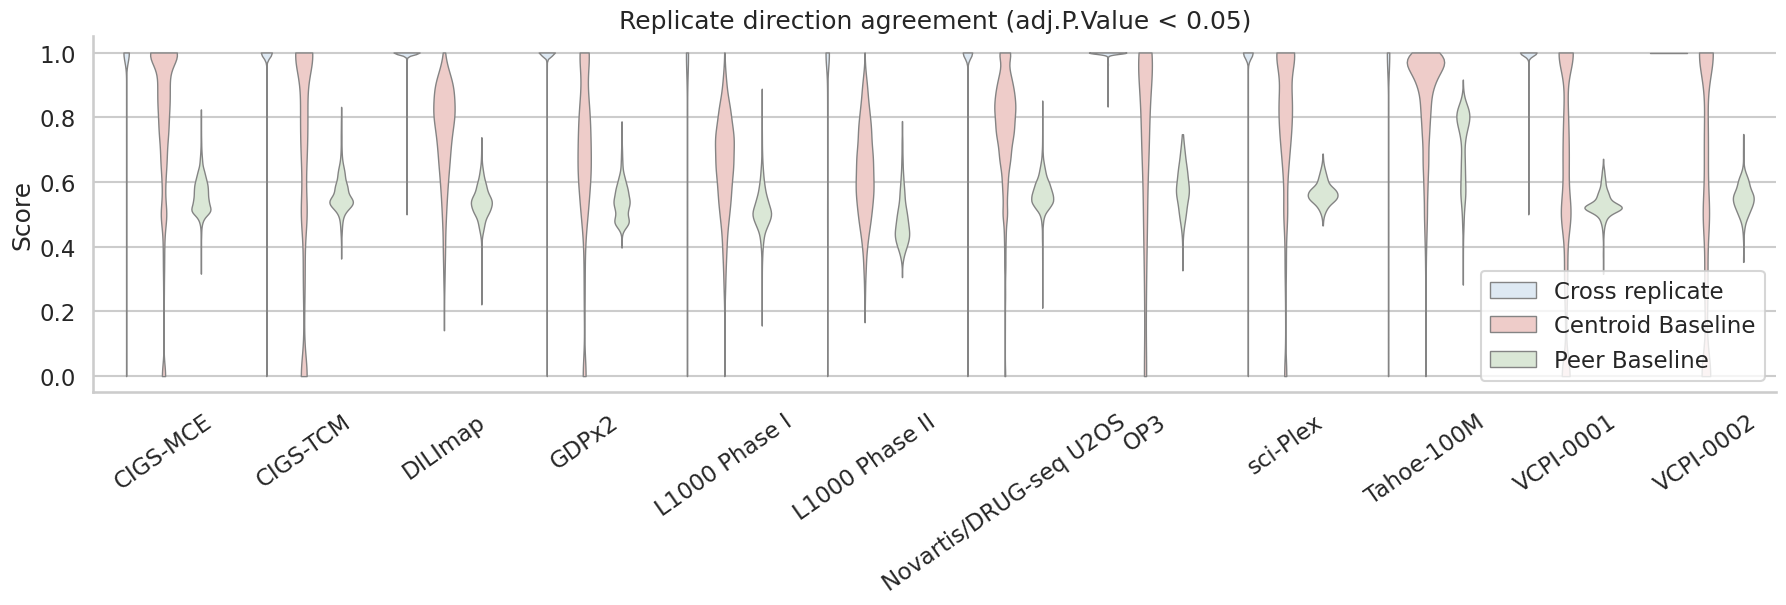

Saved plot to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/replicate_direction_agreement_p05_violin.pdf


,dataset_name,dataset_label,n_conditions,observed_mean,observed_median,centroid_baseline_mean,centroid_baseline_median,peer_baseline_mean,peer_baseline_median,delta_centroid,delta_peer,n_conditions_with_observed,n_conditions_with_centroid_baseline,n_conditions_with_peer_baseline
0,cigs_mce,CIGS-MCE,21426,0.963681,1.0,0.790164,0.861951,0.560559,0.553481,0.155963,0.403122,5222,16272,5222
1,cigs_tcm,CIGS-TCM,7020,0.994767,1.0,0.690375,0.793225,0.564414,0.551445,0.208180,0.430353,1687,5198,1687
2,dilimap_train_val,DILImap,1184,0.996591,1.0,0.746370,0.782474,0.539508,0.537270,0.266788,0.457066,1000,1176,995
3,gdpx2,GDPx2,2064,0.995744,1.0,0.686807,0.706721,0.540936,0.536299,0.295383,0.454808,1090,1625,1090
4,l1000_phase1,L1000 Phase I,2517,0.867639,1.0,0.648754,0.664513,0.515695,0.509602,0.191611,0.351526,1830,2437,1773
5,l1000_phase2,L1000 Phase II,2729,0.932123,1.0,0.630103,0.627019,0.483473,0.468527,0.282716,0.448541,1871,2726,1868
6,novartis_batch_2500,Novartis/DRUG-seq U2OS,15276,0.984014,1.0,0.770079,0.796671,0.565432,0.561248,0.207316,0.418582,8633,15125,8633
7,op3,OP3,541,0.998388,1.0,0.731487,0.826144,0.581826,0.579614,0.236091,0.416562,209,409,209
8,sciplex,sci-Plex,2224,0.995554,1.0,0.786060,0.833333,0.566663,0.562762,0.192816,0.428891,360,1718,360
9,tahoe,Tahoe-100M,7226,0.859374,1.0,0.849857,0.916705,0.709434,0.753208,0.002124,0.149939,5849,7186,5849


In [7]:
direction_summary = plot_violin_with_baseline(
    condition_deg_metric_summary,
    observed_col='mean_replicate_direction_agreement_p05',
    baseline_col='mean_baseline_pair_direction_agreement_p05',
    peer_baseline_col='mean_peer_baseline_direction_agreement_p05',
    centroid_delta_col='mean_delta_vs_baseline_pair_direction_agreement_p05',
    peer_delta_col='mean_delta_vs_peer_baseline_direction_agreement_p05',
    title='Replicate direction agreement (adj.P.Value < 0.05)',
    ylabel='Score',
    pdf_name='replicate_direction_agreement_p05_violin.pdf',
    
)

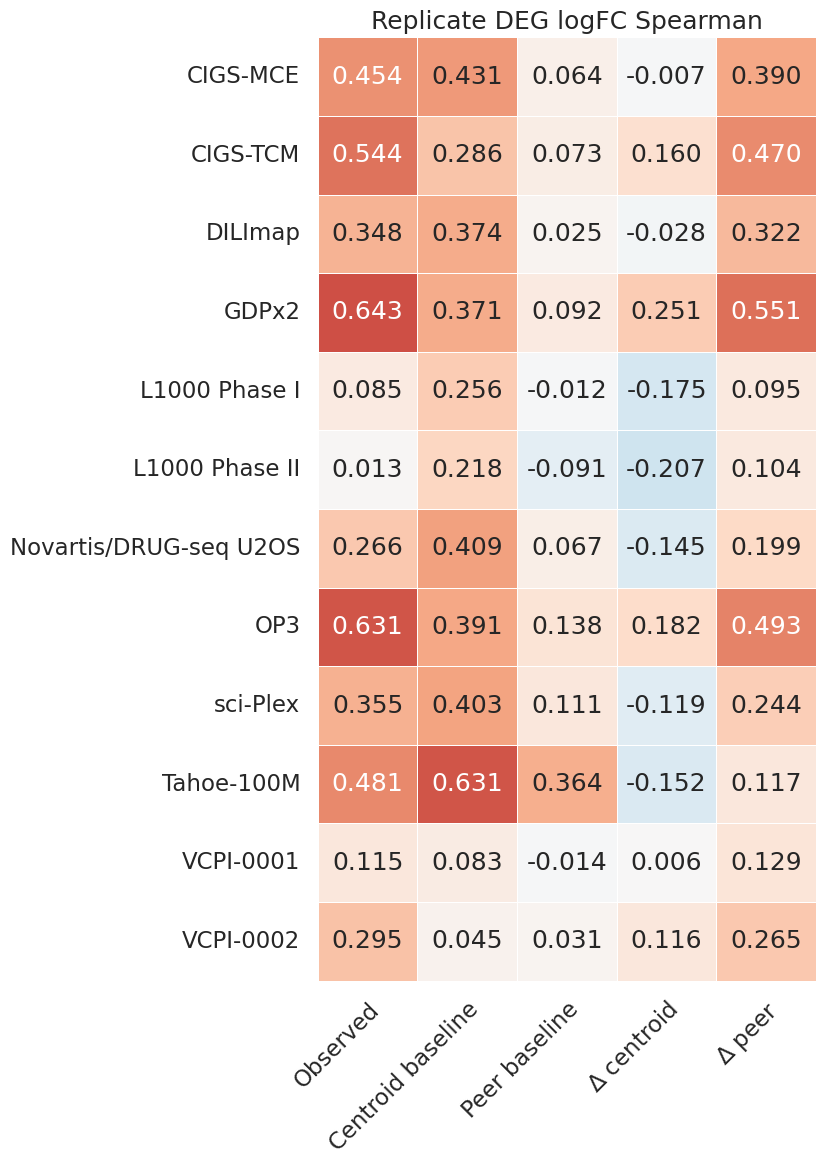

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/replicate_deg_lfc_spearman_p05_heatmap.pdf


,Observed,Centroid baseline,Peer baseline,$\Delta$ centroid,$\Delta$ peer
Dataset,,,,,
CIGS-MCE,0.454122,0.430808,0.063940,-0.006977,0.390182
CIGS-TCM,0.543602,0.285971,0.073219,0.160096,0.470383
DILImap,0.347947,0.374317,0.025213,-0.027539,0.322408
GDPx2,0.643370,0.370705,0.092086,0.250806,0.551284
L1000 Phase I,0.085425,0.256161,-0.011585,-0.175011,0.094663
L1000 Phase II,0.012663,0.218361,-0.091290,-0.207442,0.103732
Novartis/DRUG-seq U2OS,0.266138,0.409245,0.067373,-0.144941,0.198765
OP3,0.631333,0.391289,0.138073,0.181896,0.493260
sci-Plex,0.354706,0.403320,0.110902,-0.119458,0.243804


In [8]:
# Heatmap: DEG logFC Spearman
shared_heatmap_vmin, shared_heatmap_vmax = shared_summary_heatmap_limits(deg_lfc_summary, direction_summary)

deg_lfc_heatmap = plot_summary_heatmap(
    deg_lfc_summary,
    title='Replicate DEG logFC Spearman',
    value_label='',
    pdf_name='replicate_deg_lfc_spearman_p05_heatmap.pdf',
    vmin=shared_heatmap_vmin,
    vmax=shared_heatmap_vmax,
    show_colorbar=False,
)

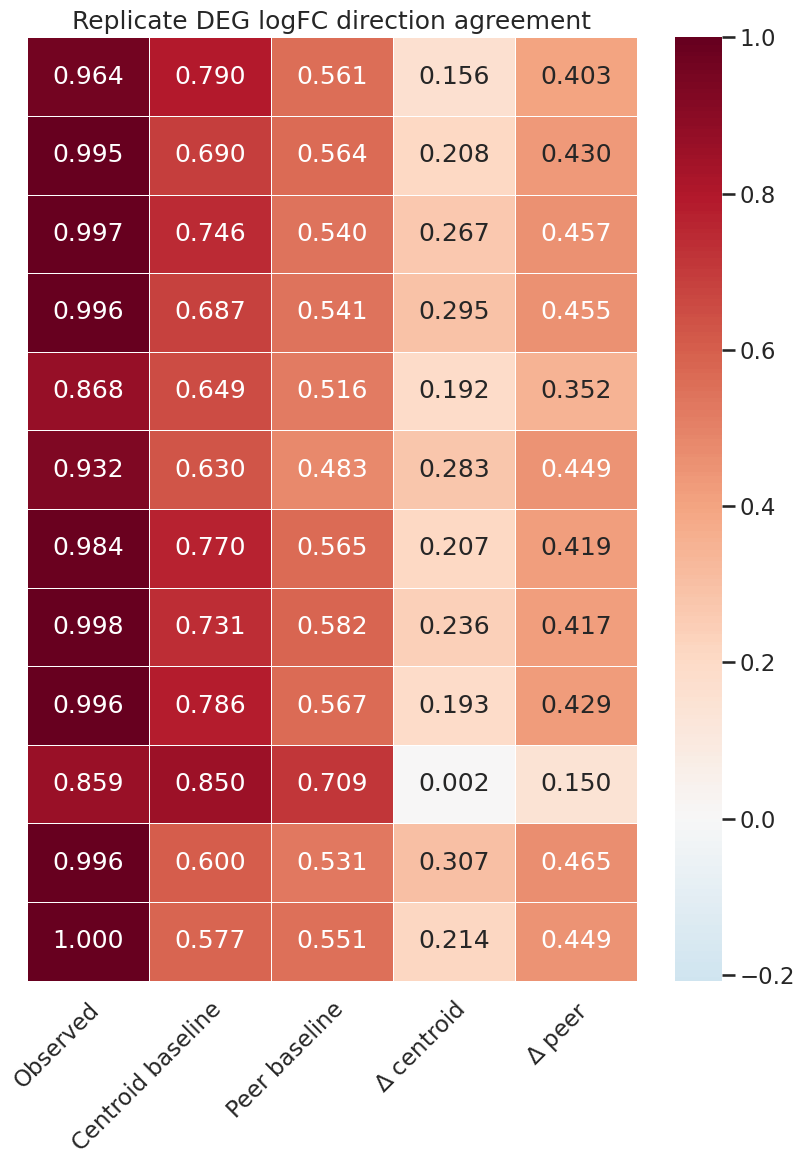

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/replicate_direction_agreement_p05_heatmap.pdf


,Observed,Centroid baseline,Peer baseline,$\Delta$ centroid,$\Delta$ peer
Dataset,,,,,
CIGS-MCE,0.963681,0.790164,0.560559,0.155963,0.403122
CIGS-TCM,0.994767,0.690375,0.564414,0.208180,0.430353
DILImap,0.996591,0.746370,0.539508,0.266788,0.457066
GDPx2,0.995744,0.686807,0.540936,0.295383,0.454808
L1000 Phase I,0.867639,0.648754,0.515695,0.191611,0.351526
L1000 Phase II,0.932123,0.630103,0.483473,0.282716,0.448541
Novartis/DRUG-seq U2OS,0.984014,0.770079,0.565432,0.207316,0.418582
OP3,0.998388,0.731487,0.581826,0.236091,0.416562
sci-Plex,0.995554,0.786060,0.566663,0.192816,0.428891


In [9]:
# Heatmap: direction agreement
direction_heatmap = plot_summary_heatmap(
    direction_summary,
    title='Replicate DEG logFC direction agreement',
    value_label='',
    pdf_name='replicate_direction_agreement_p05_heatmap.pdf',
    vmin=shared_heatmap_vmin,
    vmax=shared_heatmap_vmax,
    show_dataset_labels=False,
)